# **Fase 4a · Detecção de eventos sonoros**
### *Aplica o PANNs e o CLAP às cinco faixas, sem e com filtro, em janelas de 2 segundos, conforme `docs/fase4/02_desenho_experimental.md`, e salva cada execução em JSON. Requer acesso aos áudios e GPU.*

(A comparação com a tabela de eventos de referência está no caderno 4b, que lê apenas os JSON produzidos aqui)

## **1. Preparação do ambiente**

*Instala o pacote do PANNs (`panns-inference`), que traz a arquitetura do modelo e a lista das 527 categorias do AudioSet, e o filtro de ruído da fase 3. O CLAP é carregado pela biblioteca `transformers`, já presente no Colab. O caderno exige GPU.*

In [ ]:
!pip install -q panns-inference==0.1.1 noisereduce==3.0.3

### 1.1 Drive e pastas

Conecta o Drive, define a pasta dos áudios e cria as pastas dos resultados (`resultados/fase4`) e das figuras (`figuras/fase4`).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PASTA_PROJETO = '/content/drive/MyDrive/escuta-cerrada-poc'
PASTA_AUDIOS = os.path.join(PASTA_PROJETO, 'audios')
PASTA_RESULTADOS = os.path.join(PASTA_PROJETO, 'resultados', 'fase4')
PASTA_FIGURAS = os.path.join(PASTA_PROJETO, 'figuras', 'fase4')
os.makedirs(PASTA_RESULTADOS, exist_ok=True)
os.makedirs(PASTA_FIGURAS, exist_ok=True)

ARQUIVOS = sorted(os.listdir(PASTA_AUDIOS))
for i, nome in enumerate(ARQUIVOS, start=1):
    print(i, nome)

Mounted at /content/drive
1 1. 27230 - Concentração trabalhista no estádio do Pacaembú - 01-05-1944.mp3
2 2. Dia de Verão Gaúcho.wav
3 3. 27240 - Doutrina policial - é a prostituição um mal necessário - 1944 - Experiência de gravação (B).mp3
4 4. 27698 - Ritmos de samba - Almirante.wav
5 5. Descobrimento do Brasil.mp4


### 1.2 Versões, GPU e avisos

Registra as versões e confere a GPU. Silencia os avisos do librosa sobre a leitura do MP4 da faixa 05, que não indicam erro.

In [ ]:
import sys, importlib.metadata as md, torch, warnings
warnings.filterwarnings('ignore', message='PySoundFile failed')
warnings.filterwarnings('ignore', category=FutureWarning)

VERSOES = {p: md.version(p) for p in
           ['panns-inference', 'torchlibrosa', 'transformers', 'noisereduce', 'librosa', 'numpy', 'torch']}
print('Python', sys.version.split()[0])
for p, v in VERSOES.items():
    print(p, v)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nenhuma')

Python 3.13.15
panns-inference 0.1.1
torchlibrosa 0.1.0
transformers 5.20.1
noisereduce 3.0.3
librosa 0.11.0
numpy 2.1.3
torch 2.11.0+cu130
GPU: Tesla T4


**Resultado.** GPU Tesla T4 ativa e Python 3.13.15. As versões ficam gravadas em cada JSON, porque o Colab atualiza o ambiente sem aviso. As seções 1 e 2 foram executadas de novo em 21/10, em CPU, para a escuta dirigida (seção 7), e a saída desta célula, que essa nova execução havia substituído, foi restaurada a partir do histórico de revisões do Colab, para corresponder à execução que produziu os JSON.

## **2. Entrada e janelas**

*Carrega cada faixa como soma dos canais dividida por dois, reamostrada para a taxa de cada modelo (32 kHz no PANNs, 48 kHz no CLAP), aplica o filtro quando a condição o prevê e divide o sinal em janelas de 2 segundos com passo de 1 segundo. A última janela é ajustada para terminar exatamente no fim da faixa, de modo que nenhum trecho fique de fora e nenhuma janela seja completada com silêncio artificial.*

In [ ]:
import librosa
import numpy as np
import noisereduce as nr

JANELA_S, PASSO_S = 2.0, 1.0

def carregar(n, taxa, filtro=False):
    caminho = os.path.join(PASTA_AUDIOS, ARQUIVOS[n - 1])
    sinal, _ = librosa.load(caminho, sr=taxa, mono=False)
    mono = (sinal[0] + sinal[1]) / 2 if sinal.ndim == 2 else sinal
    mono = mono.astype(np.float32)
    if filtro:
        mono = nr.reduce_noise(y=mono, sr=taxa).astype(np.float32)
    return mono

def janelas(audio, taxa):
    """Devolve a lista de (início, fim) em segundos e a matriz com o sinal de cada janela."""
    duracao = len(audio) / taxa
    inicios = list(np.arange(0, duracao - JANELA_S + 1e-9, PASSO_S))
    if inicios[-1] + JANELA_S < duracao:
        inicios.append(duracao - JANELA_S)
    n = int(JANELA_S * taxa)
    trechos = np.stack([audio[int(round(i * taxa)):int(round(i * taxa)) + n] for i in inicios])
    return [(round(float(i), 3), round(float(i) + JANELA_S, 3)) for i in inicios], trechos

for n in range(1, 6):
    tempos, _ = janelas(carregar(n, 32000), 32000)
    print(n, len(tempos), 'janelas · última:', tempos[-1])

1 335 janelas · última: (333.517, 335.517)
2 201 janelas · última: (199.323, 201.323)
3 362 janelas · última: (360.057, 362.057)
4 64 janelas · última: (62.864, 64.864)
5 441 janelas · última: (439.318, 441.318)


**Resultado.** As faixas foram divididas em 335, 201, 362, 64 e 441 janelas. Como as durações não são múltiplas exatas de 1 segundo, a última janela de cada faixa começa numa posição fracionária (333,5 s na faixa 01, por exemplo) e termina exatamente no fim do arquivo.

## **3. PANNs**

*Baixa os pesos do modelo Cnn14, depositados pelos autores no Zenodo, e monta o modelo. A montagem é feita diretamente, sem a função pronta do pacote, porque as versões recentes do PyTorch recusam por padrão o formato em que esses pesos foram salvos, e a leitura precisa ser autorizada explicitamente (`weights_only=False`). Os pesos vêm da fonte oficial e foram publicados pelos próprios autores do modelo.*

In [ ]:
!mkdir -p /content/panns_data
!wget -q -nc -O /content/panns_data/Cnn14_mAP=0.431.pth "https://zenodo.org/record/3987831/files/Cnn14_mAP%3D0.431.pth?download=1"
!ls -la /content/panns_data

total 319768
drwxr-xr-x 2 root root      4096 Oct 20 15:29  .
drwxr-xr-x 1 root root      4096 Oct 20 15:29  ..
-rw-r--r-- 1 root root 327428481 Oct 20 15:32 'Cnn14_mAP=0.431.pth'


In [ ]:
from panns_inference.models import Cnn14
from panns_inference.config import labels as ROTULOS_AUDIOSET

DISPOSITIVO = 'cuda' if torch.cuda.is_available() else 'cpu'
CHECKPOINT_PANNS = '/content/panns_data/Cnn14_mAP=0.431.pth'

panns = Cnn14(sample_rate=32000, window_size=1024, hop_size=320, mel_bins=64,
              fmin=50, fmax=14000, classes_num=527)
estado = torch.load(CHECKPOINT_PANNS, map_location=DISPOSITIVO, weights_only=False)
panns.load_state_dict(estado['model'])
panns.to(DISPOSITIVO).eval()
print(len(ROTULOS_AUDIOSET), 'categorias ·', ROTULOS_AUDIOSET[:3], '...')

527 categorias · ['Speech', 'Male speech, man speaking', 'Female speech, woman speaking'] ...


### 3.1 Função de execução

Aplica o PANNs a todas as janelas de uma faixa, em lotes de 32 janelas, e grava um JSON com a configuração e, para cada janela, todos os rótulos com probabilidade de pelo menos 0,01, conforme a seção 8 do desenho experimental.

In [ ]:
import json, time
from datetime import datetime, timezone

LIMIAR_REGISTRO = 0.01

def probabilidades_panns(trechos):
    saidas = []
    with torch.no_grad():
        for i in range(0, len(trechos), 32):
            lote = torch.from_numpy(trechos[i:i + 32]).to(DISPOSITIVO)
            saidas.append(panns(lote, None)['clipwise_output'].cpu().numpy())
    return np.concatenate(saidas)

def executar_panns(n, condicao, sufixo='', salvar=True):
    audio = carregar(n, 32000, filtro=(condicao == 'com'))
    tempos, trechos = janelas(audio, 32000)
    inicio = time.time()
    probs = probabilidades_panns(trechos)
    duracao = time.time() - inicio
    registro = {
        'faixa': n, 'arquivo': ARQUIVOS[n - 1], 'modelo': 'PANNs Cnn14',
        'pesos': 'Cnn14_mAP=0.431.pth', 'condicao': condicao, 'filtro': condicao == 'com',
        'taxa_hz': 32000, 'janela_s': JANELA_S, 'passo_s': PASSO_S,
        'limiar_registro': LIMIAR_REGISTRO,
        'versoes': VERSOES, 'python': sys.version.split()[0],
        'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nenhuma',
        'data_execucao': datetime.now(timezone.utc).isoformat(),
        'duracao_audio_s': round(len(audio) / 32000, 2),
        'duracao_processamento_s': round(duracao, 2),
        'janelas': [
            {'inicio': a, 'fim': b,
             'rotulos': {ROTULOS_AUDIOSET[k]: round(float(p[k]), 4)
                         for k in np.argsort(-p) if p[k] >= LIMIAR_REGISTRO}}
            for (a, b), p in zip(tempos, probs)
        ],
    }
    if salvar:
        nome = f'faixa{n:02d}_panns_{condicao}{sufixo}.json'
        with open(os.path.join(PASTA_RESULTADOS, nome), 'w', encoding='utf-8') as f:
            json.dump(registro, f, ensure_ascii=False, indent=1)
        print(f'{nome} salvo · {len(tempos)} janelas · {duracao:.1f} s')
    return registro, probs

### 3.2 Teste de determinismo

Aplica o PANNs duas vezes à faixa 04 sem filtro e compara as probabilidades até a quarta casa decimal, conforme a seção 3 do desenho experimental.

In [ ]:
r1, p1 = executar_panns(4, 'sem')
r2, p2 = executar_panns(4, 'sem', sufixo='_repeticao')
print('Probabilidades idênticas até a 4ª casa:', np.array_equal(np.round(p1, 4), np.round(p2, 4)))
print('Maior diferença absoluta:', float(np.abs(p1 - p2).max()))

faixa04_panns_sem.json salvo · 64 janelas · 2.6 s
faixa04_panns_sem_repeticao.json salvo · 64 janelas · 0.2 s
Probabilidades idênticas até a 4ª casa: True
Maior diferença absoluta: 0.0


**Resultado.** As duas execuções são idênticas, com diferença máxima igual a zero. Pela regra do desenho, cada execução rodou uma vez. O arquivo da repetição fica em `resultados/fase4/` como registro do teste e não entra nas comparações.

### 3.3 As dez execuções do PANNs

In [ ]:
for condicao in ['sem', 'com']:
    for n in range(1, 6):
        nome = f'faixa{n:02d}_panns_{condicao}.json'
        if os.path.exists(os.path.join(PASTA_RESULTADOS, nome)):
            print(f'{nome} já existe, pulando')
            continue
        executar_panns(n, condicao)

faixa01_panns_sem.json salvo · 335 janelas · 0.7 s
faixa02_panns_sem.json salvo · 201 janelas · 0.4 s
faixa03_panns_sem.json salvo · 362 janelas · 0.7 s
faixa04_panns_sem.json já existe, pulando
faixa05_panns_sem.json salvo · 441 janelas · 0.9 s
faixa01_panns_com.json salvo · 335 janelas · 0.7 s
faixa02_panns_com.json salvo · 201 janelas · 0.5 s
faixa03_panns_com.json salvo · 362 janelas · 0.8 s
faixa04_panns_com.json salvo · 64 janelas · 0.1 s
faixa05_panns_com.json salvo · 441 janelas · 0.9 s


**Resultado.** Cada execução do PANNs levou menos de um segundo de processamento. A faixa 04 sem filtro não foi executada de novo, porque já havia sido gravada no teste de determinismo.

## **4. CLAP**

*Carrega o modelo `laion/larger_clap_general` e calcula uma vez a representação de cada descrição, com o tokenizador do modelo, do vocabulário da seção 5 do desenho experimental. Em seguida, para cada janela, calcula a representação do áudio, com o extrator de características do modelo, e a semelhança (cosseno) entre ela e cada descrição. A semelhança vai de −1 a 1, e só tem sentido em comparação com as outras descrições da mesma janela.*

In [ ]:
from transformers import ClapModel, ClapProcessor

MODELO_CLAP = 'laion/larger_clap_general'
clap = ClapModel.from_pretrained(MODELO_CLAP).to(DISPOSITIVO).eval()
processador = ClapProcessor.from_pretrained(MODELO_CLAP)

MOLDE = 'This is the sound of {}.'
VOCABULARIO = [
    ('almirante_cru', 'tamborim'), ('almirante_cru', 'surdo'),
    ('almirante_cru', 'batucada'), ('almirante_cru', 'samba'),
    ('almirante_descrito', 'a tamborim, a small Brazilian frame drum played with a stick'),
    ('almirante_descrito', 'a surdo, a large Brazilian bass drum'),
    ('almirante_descrito', 'a batucada, a Brazilian samba percussion group'),
    ('classe', 'applause'), ('classe', 'a crowd cheering and shouting'),
    ('classe', 'a man coughing'), ('classe', 'a man giving a speech'),
    ('classe', 'a distorted voice'), ('classe', 'the surface noise of an old record'),
    ('classe', 'clicks of a scratched record'), ('classe', 'a skipping record'),
    ('classe', 'a page of paper being turned'), ('classe', 'music'), ('classe', 'wind'),
    ('classe', 'women singing'), ('classe', 'a church bell'), ('classe', 'footsteps'),
    ('classe', 'electrical hum'),
    ('distrator', 'silence'), ('distrator', 'a tambourine'), ('distrator', 'a snare drum'),
    ('distrator', 'a bass drum'), ('distrator', 'a door knocking'), ('distrator', 'ocean waves'),
]
TERMOS = [t for _, t in VOCABULARIO]

def vetor(saida):
    """Representação normalizada, qualquer que seja a versão da biblioteca transformers."""
    v = saida if torch.is_tensor(saida) else saida.pooler_output
    return torch.nn.functional.normalize(v, dim=-1)

with torch.no_grad():
    entrada = processador.tokenizer([MOLDE.format(t) for t in TERMOS], padding=True, return_tensors='pt')
    entrada = {k: v.to(DISPOSITIVO) for k, v in entrada.items()}
    TEXTO = vetor(clap.get_text_features(**entrada))
print(len(TERMOS), 'descrições · dimensão', TEXTO.shape[1])

config.json:   0%|          | 0.00/643 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  776MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/555 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  776MB            

...

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

28 descrições · dimensão 512


**Resultado.** O aviso sobre "unauthenticated requests" indica apenas que os pesos do CLAP foram baixados do Hugging Face sem identificação de conta. O modelo é público e não exige chave, e o aviso não afeta o download nem os resultados. Nenhuma chave de acesso foi usada neste caderno. Se uma chave for necessária em fases futuras, ela será lida dos Secrets do Colab, e nunca escrita no código.

### 4.1 Função de execução

Calcula, para cada janela, a semelhança com todas as descrições e grava um JSON com a configuração, o vocabulário e as semelhanças, conforme a seção 8 do desenho experimental.

In [ ]:
def semelhancas_clap(trechos):
    saidas = []
    with torch.no_grad():
        for i in range(0, len(trechos), 16):
            entrada = processador.feature_extractor(list(trechos[i:i + 16]), sampling_rate=48000, return_tensors='pt')
            entrada = {k: v.to(DISPOSITIVO) for k, v in entrada.items()}
            audio = vetor(clap.get_audio_features(**entrada))
            saidas.append((audio @ TEXTO.T).cpu().numpy())
    return np.concatenate(saidas)

def executar_clap(n, condicao):
    audio = carregar(n, 48000, filtro=(condicao == 'com'))
    tempos, trechos = janelas(audio, 48000)
    inicio = time.time()
    sims = semelhancas_clap(trechos)
    duracao = time.time() - inicio
    registro = {
        'faixa': n, 'arquivo': ARQUIVOS[n - 1], 'modelo': MODELO_CLAP,
        'condicao': condicao, 'filtro': condicao == 'com',
        'taxa_hz': 48000, 'janela_s': JANELA_S, 'passo_s': PASSO_S, 'molde': MOLDE,
        'vocabulario': [{'grupo': g, 'termo': t} for g, t in VOCABULARIO],
        'versoes': VERSOES, 'python': sys.version.split()[0],
        'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nenhuma',
        'data_execucao': datetime.now(timezone.utc).isoformat(),
        'duracao_audio_s': round(len(audio) / 48000, 2),
        'duracao_processamento_s': round(duracao, 2),
        'janelas': [
            {'inicio': a, 'fim': b,
             'semelhancas': {t: round(float(s), 4) for t, s in zip(TERMOS, linha)}}
            for (a, b), linha in zip(tempos, sims)
        ],
    }
    nome = f'faixa{n:02d}_clap_{condicao}.json'
    with open(os.path.join(PASTA_RESULTADOS, nome), 'w', encoding='utf-8') as f:
        json.dump(registro, f, ensure_ascii=False, indent=1)
    print(f'{nome} salvo · {len(tempos)} janelas · {duracao:.1f} s')
    return registro, sims

### 4.2 As dez execuções do CLAP

In [ ]:
for condicao in ['sem', 'com']:
    for n in range(1, 6):
        nome = f'faixa{n:02d}_clap_{condicao}.json'
        if os.path.exists(os.path.join(PASTA_RESULTADOS, nome)):
            print(f'{nome} já existe, pulando')
            continue
        executar_clap(n, condicao)

faixa01_clap_sem.json salvo · 335 janelas · 34.9 s
faixa02_clap_sem.json salvo · 201 janelas · 11.8 s
faixa03_clap_sem.json salvo · 362 janelas · 20.8 s
faixa04_clap_sem.json salvo · 64 janelas · 3.6 s
faixa05_clap_sem.json salvo · 441 janelas · 24.9 s
faixa01_clap_com.json salvo · 335 janelas · 22.3 s
faixa02_clap_com.json salvo · 201 janelas · 11.5 s
faixa03_clap_com.json salvo · 362 janelas · 26.2 s
faixa04_clap_com.json salvo · 64 janelas · 3.8 s
faixa05_clap_com.json salvo · 441 janelas · 25.1 s


**Resultado.** As execuções do CLAP levaram de 3,6 a 34,9 segundos, bem mais que as do PANNs, porque o modelo completa cada janela de 2 segundos até 10 segundos, repetindo o próprio trecho, antes de calcular a representação do áudio.

## **5. Visão geral**

*Para cada faixa, na condição sem filtro, mostra os rótulos do PANNs que chegaram a 0,3 em alguma janela, com a probabilidade ao longo do tempo, e as três descrições do CLAP mais frequentes em primeiro lugar. É uma leitura inicial das saídas, sem comparação com a referência, que fica para o caderno 4b.*

In [ ]:
import pandas as pd

def ler(n, modelo, condicao):
    with open(os.path.join(PASTA_RESULTADOS, f'faixa{n:02d}_{modelo}_{condicao}.json'), encoding='utf-8') as f:
        return json.load(f)

def mmss(s):
    return f'{int(s // 60)}:{s % 60:04.1f}'

for n in range(1, 6):
    r = ler(n, 'panns', 'sem')
    maximos = {}
    for j in r['janelas']:
        for rotulo, p in j['rotulos'].items():
            if p >= 0.3 and p > maximos.get(rotulo, (0, 0))[0]:
                maximos[rotulo] = (p, j['inicio'])
    print(f"\nFaixa {n:02d} · PANNs, rótulos que chegaram a 0,3 (máximo e tempo do máximo)")
    for rotulo, (p, t) in sorted(maximos.items(), key=lambda x: -x[1][0]):
        print(f'   {rotulo}: {p:.2f} em {mmss(t)}')
    c = ler(n, 'clap', 'sem')
    primeiros = pd.Series([max(j['semelhancas'], key=j['semelhancas'].get) for j in c['janelas']])
    print(f'Faixa {n:02d} · CLAP, descrições mais frequentes em primeiro lugar')
    for termo, k in primeiros.value_counts().head(3).items():
        print(f'   {termo}: {k} de {len(primeiros)} janelas')


Faixa 01 · PANNs, rótulos que chegaram a 0,3 (máximo e tempo do máximo)
   Speech: 0.92 em 3:51.0
   Applause: 0.82 em 3:57.0
   Narration, monologue: 0.62 em 1:34.0
   Male speech, man speaking: 0.62 em 1:34.0
   Sheep: 0.57 em 4:56.0
   Noise: 0.44 em 2:24.0
   Bleat: 0.41 em 4:56.0
   Radio: 0.35 em 1:58.0
   Vehicle: 0.33 em 0:47.0
   Machine gun: 0.33 em 5:25.0
   Eruption: 0.32 em 3:46.0
   Gunshot, gunfire: 0.31 em 5:25.0
   Speech synthesizer: 0.31 em 2:49.0
Faixa 01 · CLAP, descrições mais frequentes em primeiro lugar
   the surface noise of an old record: 241 de 335 janelas
   a man giving a speech: 88 de 335 janelas
   batucada: 2 de 335 janelas

Faixa 02 · PANNs, rótulos que chegaram a 0,3 (máximo e tempo do máximo)
   Speech: 0.78 em 3:05.0
   Music: 0.73 em 1:49.0
   Static: 0.62 em 0:00.0
   Rain on surface: 0.31 em 1:28.0
Faixa 02 · CLAP, descrições mais frequentes em primeiro lugar
   the surface noise of an old record: 199 de 201 janelas
   a man giving a speech: 2 d

**Resultado.** Leitura inicial, sem comparação com a referência. Na faixa 01, "Applause" chega a 0,82 (3:57), e aparecem rótulos inesperados, como "Sheep" e "Bleat" (4:56, na tosse), "Machine gun" e "Gunshot, gunfire" (5:25) e "Eruption" (3:46). Na faixa 02, "Static" chega a 0,62 no início, e "Music", a 0,73 durante a leitura do poema. A faixa 03 tem "Gunshot, gunfire" (3:42) e "Artillery fire" (4:51). Na faixa 04, nenhum rótulo de tambor chega a 0,3, e o tamborim aparece como "Wood block" (0,39). Na faixa 05, a música tradicional recebe "Guitar", "Ukulele" e "Strum" (por volta de 1:45), a música religiosa, "Singing bowl" (0:18), o sino, "Chime" e "Wind chime" (3:55), e surgem rótulos de animais ("Bee, wasp, etc.", "Insect", "Owl", "Cattle", "Moo"). No CLAP, a descrição em primeiro lugar é quase sempre o ruído do disco nas faixas 01, 02 e 04, a fala e o ruído na faixa 03, e a fala, a música e a palavra "surdo" na faixa 05. As comparações estão no caderno 4b.

### 5.1 Figuras

Desenha, para cada faixa na condição sem filtro, o espectrograma mel da soma dos canais e, abaixo, a probabilidade dos rótulos do PANNs que chegaram a 0,3 em alguma janela, no centro de cada janela. As figuras são salvas na pasta `figuras/fase4`.

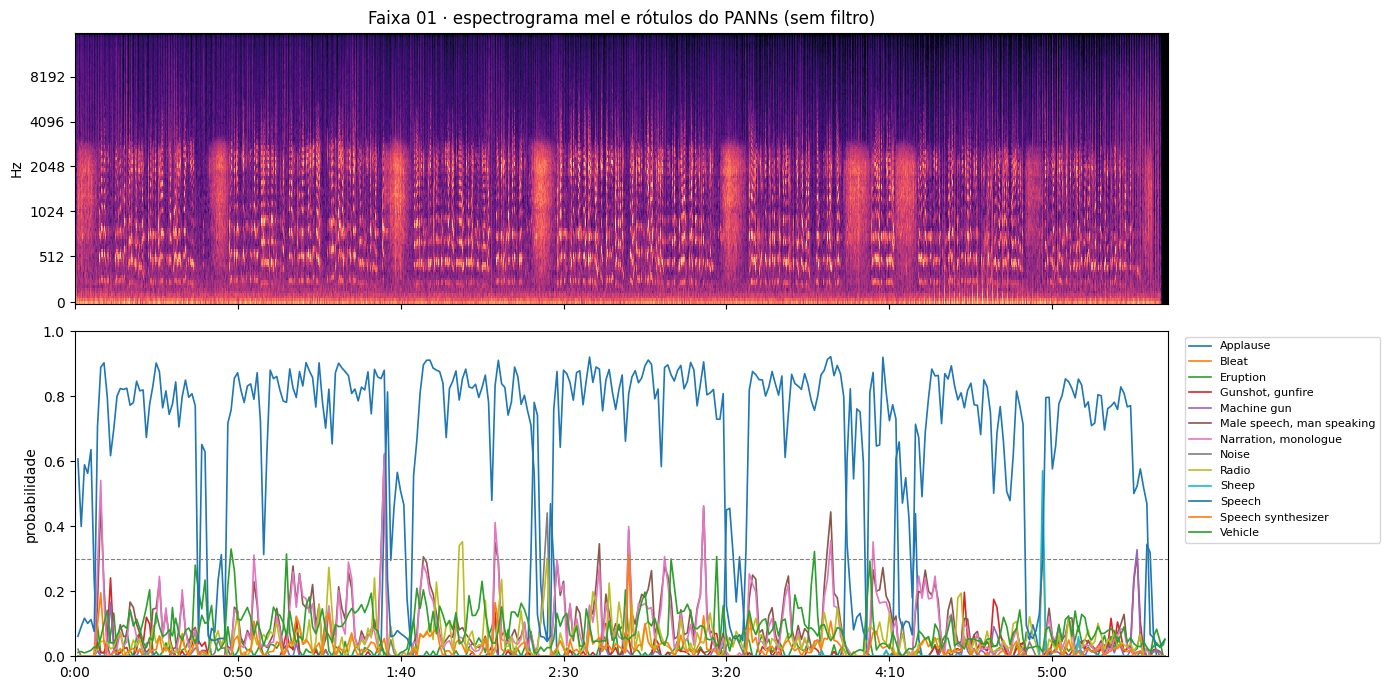

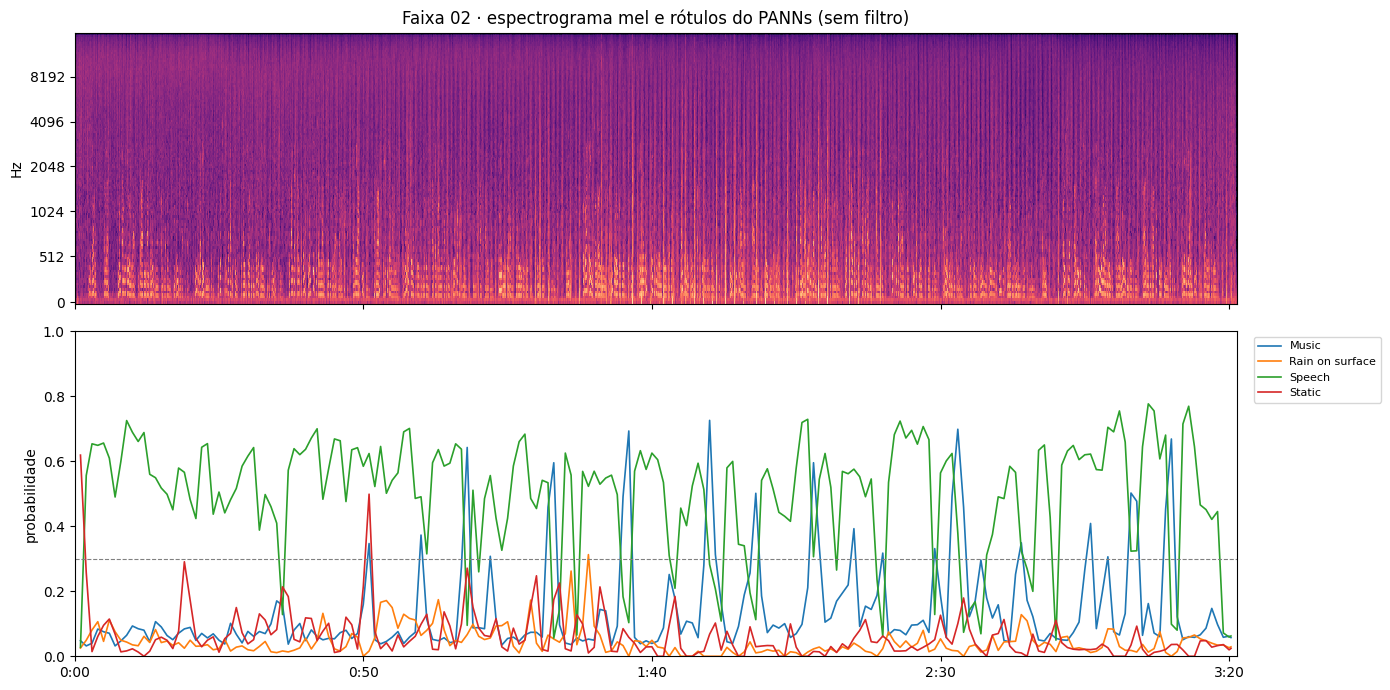

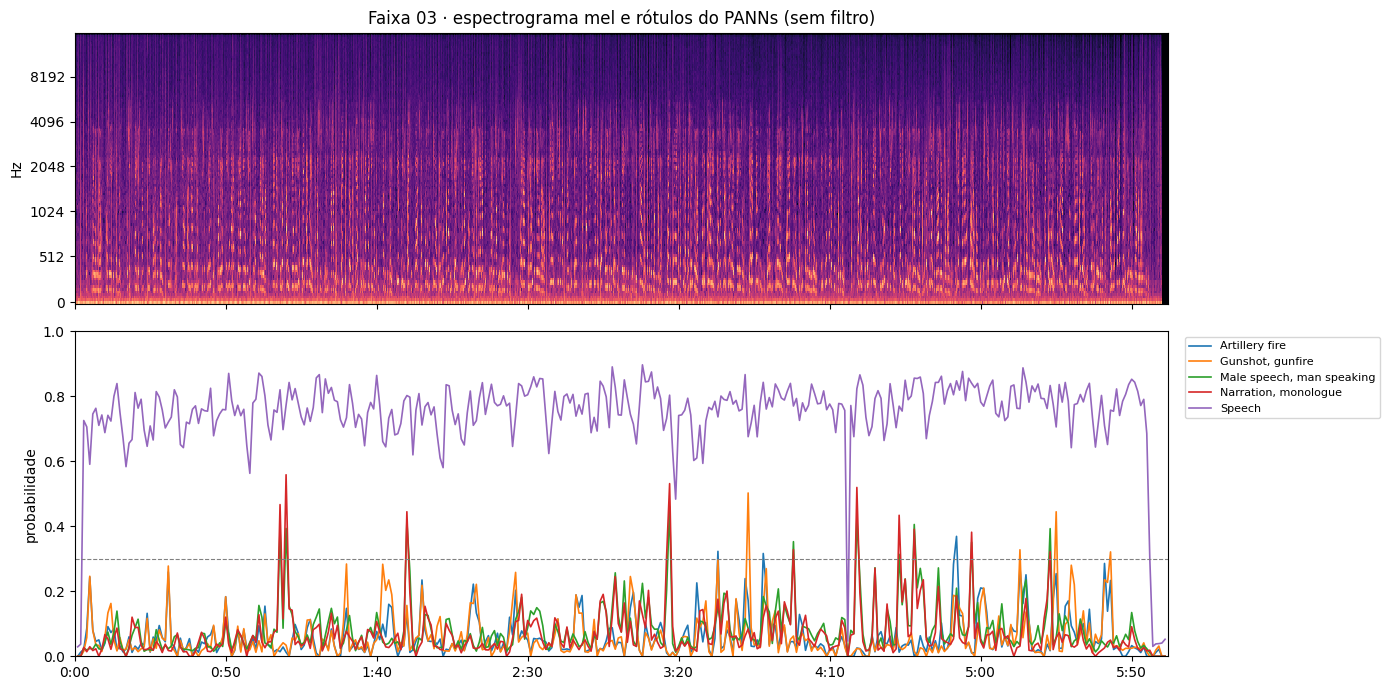

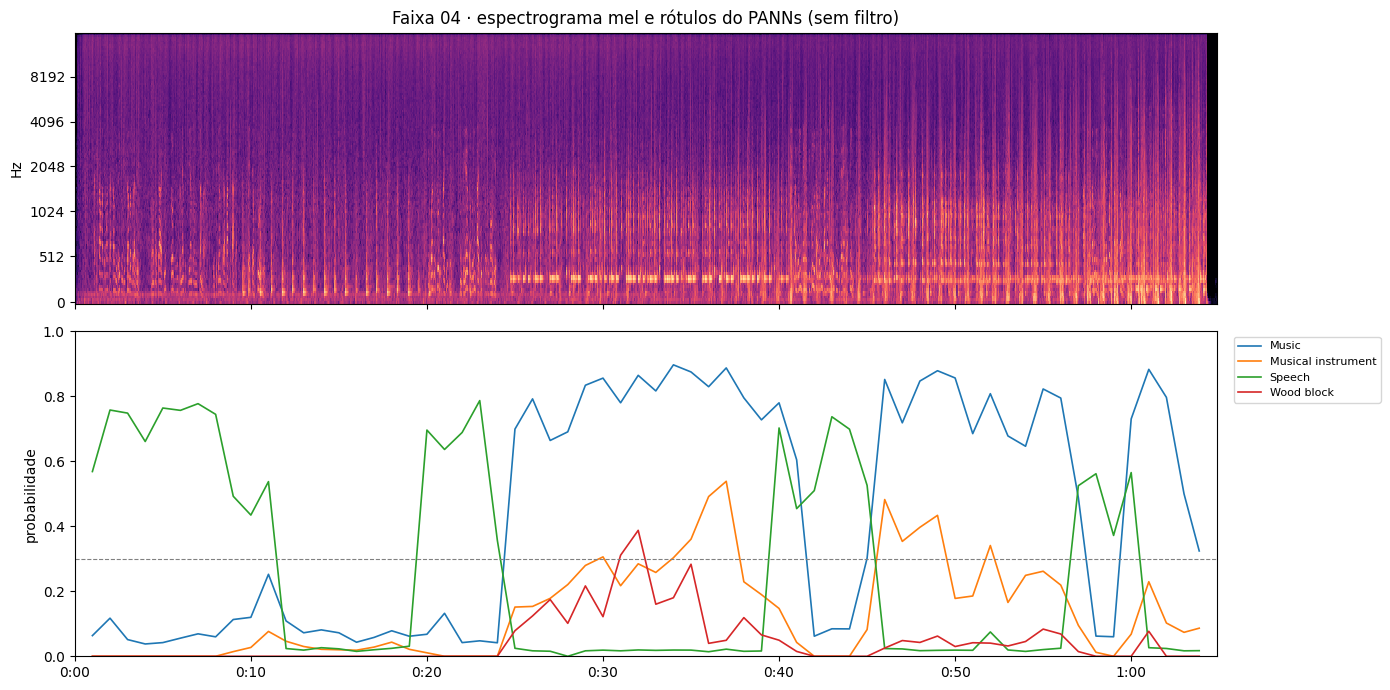

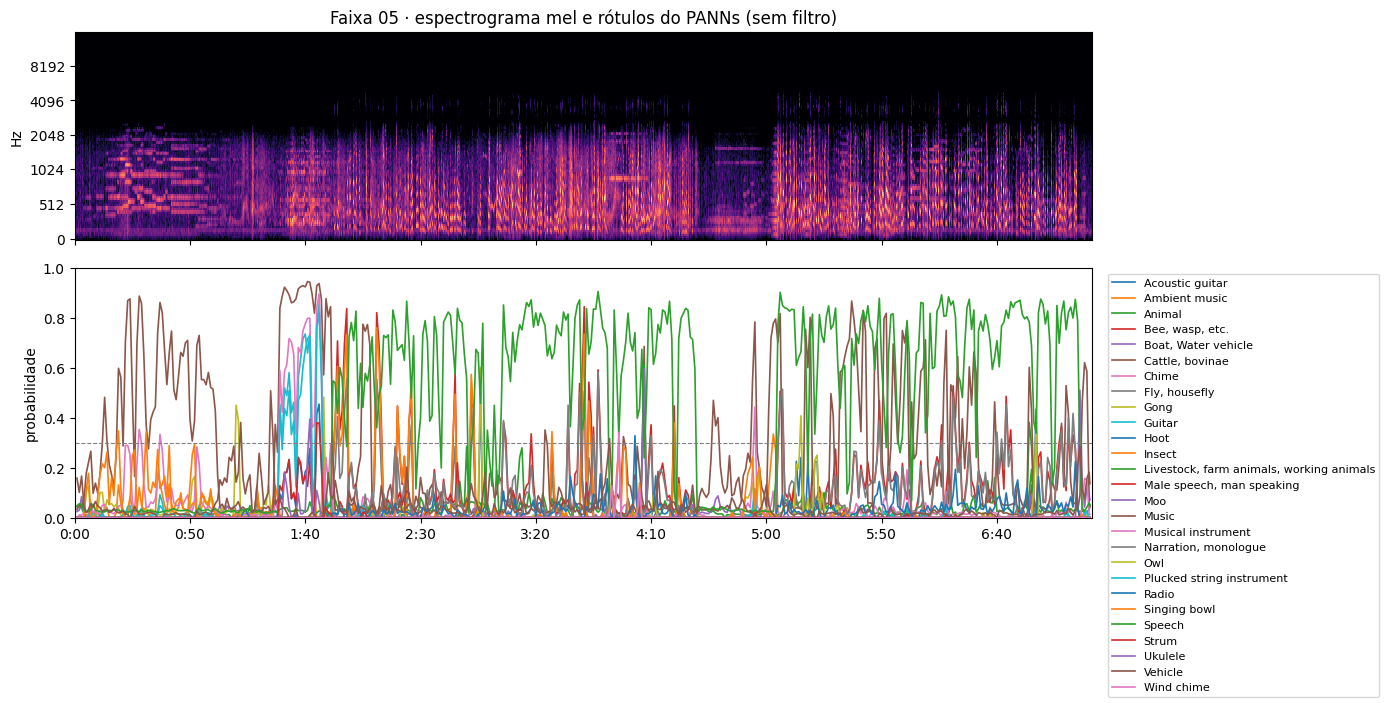

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

formato = FuncFormatter(lambda x, _: f'{int(x // 60)}:{int(x % 60):02d}')

def figura(n):
    r = ler(n, 'panns', 'sem')
    sinal = carregar(n, 32000)
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=sinal, sr=32000, n_mels=128), ref=np.max)
    centros = [(j['inicio'] + j['fim']) / 2 for j in r['janelas']]
    rotulos = sorted({k for j in r['janelas'] for k, p in j['rotulos'].items() if p >= 0.3})
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                                 gridspec_kw={'height_ratios': [1, 1.2]})
    librosa.display.specshow(S, sr=32000, x_axis='time', y_axis='mel', ax=a1, cmap='magma')
    a1.set_title(f'Faixa {n:02d} · espectrograma mel e rótulos do PANNs (sem filtro)')
    a1.set_xlabel('')
    for rotulo in rotulos:
        a2.plot(centros, [j['rotulos'].get(rotulo, 0) for j in r['janelas']], label=rotulo, lw=1.2)
    a2.axhline(0.3, color='gray', ls='--', lw=0.8)
    a2.set_ylim(0, 1)
    a2.set_ylabel('probabilidade')
    a2.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
    a2.xaxis.set_major_formatter(formato)
    plt.tight_layout()
    fig.savefig(os.path.join(PASTA_FIGURAS, f'faixa{n:02d}_panns.png'), dpi=120, bbox_inches='tight')
    plt.show()

import librosa.display
for n in range(1, 6):
    figura(n)

**Resultado.** As figuras estão em `docs/fase4/figuras/`. Nos espectrogramas, os aplausos da faixa 01 aparecem como faixas verticais de energia em todas as frequências, e o silêncio do fim da mesma faixa, como uma faixa escura. A paleta padrão tem dez cores, e rótulos diferentes podem receber a mesma cor (na faixa 01, "Applause" e "Speech", por exemplo), de modo que a leitura deve se apoiar nos nomes da legenda e nos valores da seção 5.

## **6. Ambiente de execução**

In [ ]:
print(datetime.now(timezone.utc).isoformat())
print('Python', sys.version.split()[0])
for p, v in VERSOES.items():
    print(p, v)

2026-10-20T15:46:38.357802+00:00
Python 3.13.15
panns-inference 0.1.1
torchlibrosa 0.1.0
transformers 5.20.1
noisereduce 3.0.3
librosa 0.11.0
numpy 2.1.3
torch 2.11.0+cu130


## **7. Escuta dirigida**

*Toca cada trecho da lista gerada pelo caderno 4b (seção 10), a partir do arquivo original (soma dos canais, sem reamostragem), com três segundos de folga antes e depois. Por padrão, os rótulos dos detectores não são exibidos, para que a primeira escuta não seja orientada por eles. Com `mostrar_rotulos=True`, a função mostra, para cada modelo e condição, os rótulos que levaram o trecho à lista, com o valor máximo e o número de janelas. Com `filtro=True`, toca o trecho como os detectores o receberam na condição com filtro (filtro aplicado à faixa inteira, a 48 kHz), para conferir os rótulos que só aparecem nessa condição.*

In [ ]:
import pandas as pd
from IPython.display import Audio, display

def tempo(s):
    return f'{int(s // 60)}:{s % 60:04.1f}'.replace('.', ',')

ESCUTA = pd.read_csv(os.path.join(PASTA_RESULTADOS, 'medidas', 'escuta_dirigida.csv'))
_FILTRADAS = {}

def ouvir_trecho(t, mostrar_rotulos=False, filtro=False, margem=3):
    g = ESCUTA[ESCUTA['trecho'] == t]
    n = int(g['faixa'].iloc[0])
    inicio = max(0, g['inicio'].min() - margem)
    fim = g['fim'].max() + margem
    if filtro:
        if n not in _FILTRADAS:
            _FILTRADAS[n] = carregar(n, 48000, filtro=True)
        mono, taxa = _FILTRADAS[n][int(inicio * 48000):int(fim * 48000)], 48000
    else:
        caminho = os.path.join(PASTA_AUDIOS, ARQUIVOS[n - 1])
        sinal, taxa = librosa.load(caminho, sr=None, mono=False, offset=inicio, duration=fim - inicio)
        mono = (sinal[0] + sinal[1]) / 2 if sinal.ndim == 2 else sinal
    print(f"Trecho {t} · faixa {n:02d} · {tempo(g['inicio'].min())} a {tempo(g['fim'].max())}"
          f" (tocando de {tempo(inicio)} a {tempo(fim)}{', com filtro' if filtro else ''})")
    if mostrar_rotulos:
        resumo = g.groupby(['modelo', 'condicao', 'criterio', 'rotulo'])['valor'].agg(['max', 'size']).reset_index()
        for _, l in resumo.iterrows():
            valor = f"{l['max']:.2f}" if l['modelo'] == 'PANNs' else '1º lugar'
            print(f"   {l['modelo']} {l['condicao']} · critério {l['criterio']} · {l['rotulo']} · {valor} · {l['size']} janela(s)")
    display(Audio(mono, rate=taxa))

Cada trecho é tocado trocando o número na chamada abaixo, de 1 a 34. A primeira escuta é feita sem os rótulos, e a segunda com `ouvir_trecho(n, mostrar_rotulos=True)` ou com a lista do caderno de preenchimento. Quando um rótulo só aparece na condição com filtro, vale ouvir também `ouvir_trecho(n, filtro=True)`. O registro da escuta está em `docs/fase4/03_escuta_dirigida.md`.

In [ ]:
ouvir_trecho(1)

Trecho 1 · faixa 01 · 0:00,0 a 0:06,0 (tocando de 0:00,0 a 0:09,0)


In [ ]:
ouvir_trecho(2)

Trecho 2 · faixa 01 · 1:34,0 a 1:36,0 (tocando de 1:31,0 a 1:39,0)


In [ ]:
ouvir_trecho(2, filtro=True)

Trecho 2 · faixa 01 · 1:34,0 a 1:36,0 (tocando de 1:31,0 a 1:39,0, com filtro)


In [ ]:
ouvir_trecho(3)

Trecho 3 · faixa 01 · 4:11,0 a 4:13,0 (tocando de 4:08,0 a 4:16,0)


In [ ]:
ouvir_trecho(3, filtro=True)

Trecho 3 · faixa 01 · 4:11,0 a 4:13,0 (tocando de 4:08,0 a 4:16,0, com filtro)


In [ ]:
ouvir_trecho(4)

Trecho 4 · faixa 01 · 4:30,0 a 4:32,0 (tocando de 4:27,0 a 4:35,0)


In [ ]:
ouvir_trecho(4, filtro=True)

Trecho 4 · faixa 01 · 4:30,0 a 4:32,0 (tocando de 4:27,0 a 4:35,0, com filtro)


In [ ]:
ouvir_trecho(5)

Trecho 5 · faixa 01 · 4:54,0 a 4:58,0 (tocando de 4:51,0 a 5:01,0)


In [ ]:
ouvir_trecho(5, filtro=True)

Trecho 5 · faixa 01 · 4:54,0 a 4:58,0 (tocando de 4:51,0 a 5:01,0, com filtro)


In [ ]:
ouvir_trecho(6)

Trecho 6 · faixa 01 · 5:27,0 a 5:35,5 (tocando de 5:24,0 a 5:38,5)


In [ ]:
ouvir_trecho(6, filtro=True)

Trecho 6 · faixa 01 · 5:27,0 a 5:35,5 (tocando de 5:24,0 a 5:38,5, com filtro)


In [ ]:
ouvir_trecho(7)

Trecho 7 · faixa 02 · 0:02,0 a 0:19,0 (tocando de 0:00,0 a 0:22,0)


In [ ]:
ouvir_trecho(7, filtro=True)

Trecho 7 · faixa 02 · 0:02,0 a 0:19,0 (tocando de 0:00,0 a 0:22,0, com filtro)


In [ ]:
ouvir_trecho(8)

Trecho 8 · faixa 02 · 0:29,0 a 1:13,0 (tocando de 0:26,0 a 1:16,0)


In [ ]:
ouvir_trecho(8, filtro=True)

Trecho 8 · faixa 02 · 0:29,0 a 1:13,0 (tocando de 0:26,0 a 1:16,0, com filtro)


In [ ]:
ouvir_trecho(9)

Trecho 9 · faixa 02 · 1:21,0 a 1:37,0 (tocando de 1:18,0 a 1:40,0)


In [ ]:
ouvir_trecho(9, filtro=True)

Trecho 9 · faixa 02 · 1:21,0 a 1:37,0 (tocando de 1:18,0 a 1:40,0, com filtro)


In [ ]:
ouvir_trecho(10)

Trecho 10 · faixa 02 · 1:49,0 a 1:59,0 (tocando de 1:46,0 a 2:02,0)


In [ ]:
ouvir_trecho(10, filtro=True)

Trecho 10 · faixa 02 · 1:49,0 a 1:59,0 (tocando de 1:46,0 a 2:02,0, com filtro)


In [ ]:
ouvir_trecho(11)

Trecho 11 · faixa 02 · 2:07,0 a 2:35,0 (tocando de 2:04,0 a 2:38,0)


In [ ]:
ouvir_trecho(11, filtro=True)

Trecho 11 · faixa 02 · 2:07,0 a 2:35,0 (tocando de 2:04,0 a 2:38,0, com filtro)


In [ ]:
ouvir_trecho(12)

Trecho 12 · faixa 02 · 2:43,0 a 2:45,0 (tocando de 2:40,0 a 2:48,0)


In [ ]:
ouvir_trecho(12, filtro=True)

Trecho 12 · faixa 02 · 2:43,0 a 2:45,0 (tocando de 2:40,0 a 2:48,0, com filtro)


In [ ]:
ouvir_trecho(13)

Trecho 13 · faixa 02 · 2:53,0 a 3:17,0 (tocando de 2:50,0 a 3:20,0)


In [ ]:
ouvir_trecho(13, filtro=True)

Trecho 13 · faixa 02 · 2:53,0 a 3:17,0 (tocando de 2:50,0 a 3:20,0, com filtro)


In [ ]:
ouvir_trecho(14)

Trecho 14 · faixa 03 · 0:10,0 a 0:12,0 (tocando de 0:07,0 a 0:15,0)


In [ ]:
ouvir_trecho(14, filtro=True)

Trecho 14 · faixa 03 · 0:10,0 a 0:12,0 (tocando de 0:07,0 a 0:15,0, com filtro)


In [ ]:
ouvir_trecho(15)

Trecho 15 · faixa 03 · 2:12,0 a 2:14,0 (tocando de 2:09,0 a 2:17,0)


In [ ]:
ouvir_trecho(15, filtro=True)

Trecho 15 · faixa 03 · 2:12,0 a 2:14,0 (tocando de 2:09,0 a 2:17,0, com filtro)


In [ ]:
ouvir_trecho(16)

Trecho 16 · faixa 03 · 3:01,0 a 3:03,0 (tocando de 2:58,0 a 3:06,0)


In [ ]:
ouvir_trecho(16, filtro=True)

Trecho 16 · faixa 03 · 3:01,0 a 3:03,0 (tocando de 2:58,0 a 3:06,0, com filtro)


In [ ]:
ouvir_trecho(17)

Trecho 17 · faixa 03 · 3:42,0 a 3:44,0 (tocando de 3:39,0 a 3:47,0)


In [ ]:
ouvir_trecho(17, filtro=True)

Trecho 17 · faixa 03 · 3:42,0 a 3:44,0 (tocando de 3:39,0 a 3:47,0, com filtro)


In [ ]:
ouvir_trecho(18)

Trecho 18 · faixa 03 · 4:45,0 a 4:48,0 (tocando de 4:42,0 a 4:51,0)


In [ ]:
ouvir_trecho(18, filtro=True)

Trecho 18 · faixa 03 · 4:45,0 a 4:48,0 (tocando de 4:42,0 a 4:51,0, com filtro)


In [ ]:
ouvir_trecho(19)

Trecho 19 · faixa 03 · 5:38,0 a 5:40,0 (tocando de 5:35,0 a 5:43,0)


In [ ]:
ouvir_trecho(19, filtro=True)

Trecho 19 · faixa 03 · 5:38,0 a 5:40,0 (tocando de 5:35,0 a 5:43,0, com filtro)


In [ ]:
ouvir_trecho(20)

Trecho 20 · faixa 03 · 5:57,0 a 6:02,1 (tocando de 5:54,0 a 6:05,1)


In [ ]:
ouvir_trecho(20, filtro=True)

Trecho 20 · faixa 03 · 5:57,0 a 6:02,1 (tocando de 5:54,0 a 6:05,1, com filtro)


In [ ]:
ouvir_trecho(21)

Trecho 21 · faixa 04 · 0:00,0 a 0:02,0 (tocando de 0:00,0 a 0:05,0)


In [ ]:
ouvir_trecho(21, filtro=True)

Trecho 21 · faixa 04 · 0:00,0 a 0:02,0 (tocando de 0:00,0 a 0:05,0, com filtro)


In [ ]:
ouvir_trecho(22)

Trecho 22 · faixa 04 · 0:11,0 a 1:04,9 (tocando de 0:08,0 a 1:07,9)


In [ ]:
ouvir_trecho(22, filtro=True)

Trecho 22 · faixa 04 · 0:11,0 a 1:04,9 (tocando de 0:08,0 a 1:07,9, com filtro)


In [ ]:
ouvir_trecho(23)

Trecho 23 · faixa 05 · 0:18,0 a 0:21,0 (tocando de 0:15,0 a 0:24,0)


In [ ]:
ouvir_trecho(23, filtro=True)

Trecho 23 · faixa 05 · 0:18,0 a 0:21,0 (tocando de 0:15,0 a 0:24,0, com filtro)


In [ ]:
ouvir_trecho(24)

Trecho 24 · faixa 05 · 1:09,0 a 1:12,0 (tocando de 1:06,0 a 1:15,0)


In [ ]:
ouvir_trecho(24, filtro=True)

Trecho 24 · faixa 05 · 1:09,0 a 1:12,0 (tocando de 1:06,0 a 1:15,0, com filtro)


In [ ]:
ouvir_trecho(25)

Trecho 25 · faixa 05 · 1:24,0 a 1:26,0 (tocando de 1:21,0 a 1:29,0)


In [ ]:
ouvir_trecho(25, filtro=True)

Trecho 25 · faixa 05 · 1:24,0 a 1:26,0 (tocando de 1:21,0 a 1:29,0, com filtro)


In [ ]:
ouvir_trecho(26)

Trecho 26 · faixa 05 · 1:53,0 a 2:01,0 (tocando de 1:50,0 a 2:04,0)


In [ ]:
ouvir_trecho(26, filtro=True)

Trecho 26 · faixa 05 · 1:53,0 a 2:01,0 (tocando de 1:50,0 a 2:04,0, com filtro)


In [ ]:
ouvir_trecho(27)

Trecho 27 · faixa 05 · 2:08,0 a 2:13,0 (tocando de 2:05,0 a 2:16,0)


In [ ]:
ouvir_trecho(27, filtro=True)

Trecho 27 · faixa 05 · 2:08,0 a 2:13,0 (tocando de 2:05,0 a 2:16,0, com filtro)


In [ ]:
ouvir_trecho(28)

Trecho 28 · faixa 05 · 2:25,0 a 2:29,0 (tocando de 2:22,0 a 2:32,0)


In [ ]:
ouvir_trecho(28, filtro=True)

Trecho 28 · faixa 05 · 2:25,0 a 2:29,0 (tocando de 2:22,0 a 2:32,0, com filtro)


In [ ]:
ouvir_trecho(29)

Trecho 29 · faixa 05 · 2:44,0 a 4:32,0 (tocando de 2:41,0 a 4:35,0)


In [ ]:
ouvir_trecho(29, filtro=True)

Trecho 29 · faixa 05 · 2:44,0 a 4:32,0 (tocando de 2:41,0 a 4:35,0, com filtro)


In [ ]:
ouvir_trecho(30)

Trecho 30 · faixa 05 · 4:44,0 a 4:46,0 (tocando de 4:41,0 a 4:49,0)


In [ ]:
ouvir_trecho(30, filtro=True)

Trecho 30 · faixa 05 · 4:44,0 a 4:46,0 (tocando de 4:41,0 a 4:49,0, com filtro)


In [ ]:
ouvir_trecho(31)

Trecho 31 · faixa 05 · 5:13,0 a 5:15,0 (tocando de 5:10,0 a 5:18,0)


In [ ]:
ouvir_trecho(31, filtro=True)

Trecho 31 · faixa 05 · 5:13,0 a 5:15,0 (tocando de 5:10,0 a 5:18,0, com filtro)


In [ ]:
ouvir_trecho(32)

Trecho 32 · faixa 05 · 6:16,0 a 6:18,0 (tocando de 6:13,0 a 6:21,0)


In [ ]:
ouvir_trecho(32, filtro=True)

Trecho 32 · faixa 05 · 6:16,0 a 6:18,0 (tocando de 6:13,0 a 6:21,0, com filtro)


In [ ]:
ouvir_trecho(33)

Trecho 33 · faixa 05 · 6:31,0 a 6:33,0 (tocando de 6:28,0 a 6:36,0)


In [ ]:
ouvir_trecho(33, filtro=True)

Trecho 33 · faixa 05 · 6:31,0 a 6:33,0 (tocando de 6:28,0 a 6:36,0, com filtro)


In [ ]:
ouvir_trecho(34)

Trecho 34 · faixa 05 · 7:15,0 a 7:17,0 (tocando de 7:12,0 a 7:20,0)


In [ ]:
ouvir_trecho(34, filtro=True)

Trecho 34 · faixa 05 · 7:15,0 a 7:17,0 (tocando de 7:12,0 a 7:20,0, com filtro)


**Resultado.** A escuta foi feita em 21 e 22/10/2026, neste caderno, em CPU, depois de executadas de novo as seções 1 e 2. Cada trecho foi tocado na versão original e na versão com filtro, numa célula própria. Os tocadores de áudio foram retirados da versão publicada, e ficou apenas a linha que identifica cada trecho. O registro da escuta está em `docs/fase4/03_escuta_dirigida.md`.